# **SelfCheckGPT on HaluBench**

In [ ]:
# Restart after running this cell.
!pip install -q "transformers==4.36.2" selfcheckgpt sentencepiece "accelerate>=0.26,<1.0" "bitsandbytes>=0.43.0"
!python -m spacy download en_core_web_sm -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to 

In [ ]:
import os, gc, time, pickle, json, functools, warnings
from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import precision_recall_curve, auc, roc_auc_score
import spacy

warnings.filterwarnings("ignore", category=FutureWarning)
if not hasattr(spacy.load, "cache_info"):
    spacy.load = functools.lru_cache(maxsize=None)(spacy.load)
nlp = spacy.load("en_core_web_sm")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if device.type == "cuda" else 0.0
print(f"Using device: {device}" + (f" - {torch.cuda.get_device_name(0)} ({GPU_GB:.1f} GB)" if device.type == "cuda" else "  (WARNING: no GPU)"))

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTS_DIR = "/content/drive/MyDrive/ExistingDatasets"
except ImportError:
    RESULTS_DIR = "./selfcheckgpt_results"
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Results / caches ->", RESULTS_DIR)
WIKIBIO_DIRS = [RESULTS_DIR]

Using device: cuda - Tesla T4 (14.6 GB)
Mounted at /content/drive
Results / caches -> /content/drive/MyDrive/ExistingDatasets


### Configuration

In [ ]:
SEED = 42

# SelfCheckGPT variants (MQAG is omitted: far too slow for long RAG responses)
RUN_UNIGRAM   = True
RUN_BERTSCORE = True
RUN_NLI       = True
RUN_PROMPT    = True        # uses the same LLM as the sampler as the Yes/No checker

# Sampling
N_SAMPLES    = 5           
SAMPLER_LLM  = "mistralai/Mistral-7B-Instruct-v0.2"   
SAMPLER_TEMP = 1.0          # temperature used by SelfCheckGPT for its samples
GEN_BATCH    = 5            # samples generated in parallel (lower on OOM; it also falls back automatically)
HF_4BIT      = "auto"       # 4-bit NF4 if GPU < 20 GB
PROMPT_BATCH = 20

# HaluBench
HB_N_PER_SOURCE   = 20      # per source_ds, split evenly between PASS and FAIL
HB_EXCLUDE_SOURCES = ["RAGTruth"]    # HaluBench re-uses RAGTruth items; excluded to avoid overlap with the RAGTruth notebook
HB_MODES          = ["with_context", "closed_book"]
HB_MAX_CONTEXT_TOKENS = 1000   # items with a longer context are skipped (reported per source)
HB_MAX_NEW_TOKENS = 48

N_BOOT = 500               # bootstrap resamples for confidence intervals
np.random.seed(SEED); torch.manual_seed(SEED)

In [ ]:
# ---------- utilities: resumable caching, GPU clean-up ----------
def cache_path(name): return os.path.join(RESULTS_DIR, f"cache_{name}.pkl")
def load_cache(name):
    p = cache_path(name)
    if os.path.exists(p):
        with open(p, "rb") as f: return pickle.load(f)
    return {}
def save_cache(name, obj):
    p = cache_path(name); tmp = p + ".tmp"
    with open(tmp, "wb") as f: pickle.dump(obj, f)
    os.replace(tmp, p)
def run_cached(name, fn, keys, desc, save_every=10):
    cache = load_cache(name)
    todo = [k for k in keys if k not in cache]
    print(f"{desc}: {len(keys) - len(todo)} cached, {len(todo)} to compute")
    for n, k in enumerate(tqdm(todo, desc=desc)):
        cache[k] = fn(k)
        if (n + 1) % save_every == 0: save_cache(name, cache)
    if todo: save_cache(name, cache)
    return {k: cache[k] for k in keys}
def free(*names):
    for n in names: globals().pop(n, None)
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
def ram(tag=""):
    # print this process' RAM and the machine's RAM (to see how close to the Colab limit)
    import psutil
    vm = psutil.virtual_memory(); me = psutil.Process().memory_info().rss / 2**30
    print(f"[RAM {tag}] this process {me:.1f} GB | system used {vm.used / 2**30:.1f} / {vm.total / 2**30:.1f} GB")

### Models

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
llm_tok = AutoTokenizer.from_pretrained(SAMPLER_LLM, use_fast=False)   
llm_tok.padding_side = "left"
if llm_tok.pad_token is None: llm_tok.pad_token = llm_tok.eos_token
LLM = {}
OOM = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)

def get_llm():
    if "model" not in LLM:
        use_4bit = (GPU_GB < 20) if HF_4BIT == "auto" else bool(HF_4BIT)
        if use_4bit:
            LLM["model"] = AutoModelForCausalLM.from_pretrained(SAMPLER_LLM, device_map={"": 0}, low_cpu_mem_usage=True,
                quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16))
        else:
            LLM["model"] = AutoModelForCausalLM.from_pretrained(SAMPLER_LLM, torch_dtype=torch.float16, device_map={"": 0}, low_cpu_mem_usage=True)
        LLM["model"].eval()
        print(f"{SAMPLER_LLM} loaded ({'4-bit NF4' if use_4bit else 'fp16'})")
    return LLM["model"]

def chat_ids(prompt):
    return llm_tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=True, add_generation_prompt=True, return_tensors="pt")

@torch.no_grad()
def sample_responses(prompt, n, max_new_tokens, temperature=None):
    # n stochastic responses to `prompt`: pure sampling (no top-k / top-p), as in SelfCheckGPT
    temperature = SAMPLER_TEMP if temperature is None else temperature
    model = get_llm()
    ids = chat_ids(prompt).to(device)
    outs, todo, cur = [], n, GEN_BATCH
    while todo > 0:
        k = min(cur, todo)
        try:
            g = model.generate(ids, attention_mask=torch.ones_like(ids), do_sample=True, temperature=temperature, top_p=1.0, top_k=0,
                               max_new_tokens=max_new_tokens, num_return_sequences=k, pad_token_id=llm_tok.pad_token_id)
        except OOM:
            torch.cuda.empty_cache()
            if cur == 1: raise
            cur = max(1, cur // 2); print(f"OOM -> generation batch {cur}"); continue
        outs += llm_tok.batch_decode(g[:, ids.shape[1]:], skip_special_tokens=True)
        todo -= k
    return [o.strip() for o in outs]

if RUN_NLI:
    from selfcheckgpt.modeling_selfcheck import SelfCheckNLI
    selfcheck_nli = SelfCheckNLI(device=device)
    nli_tok, nli_model = selfcheck_nli.tokenizer, selfcheck_nli.model
if RUN_BERTSCORE:
    from bert_score import BERTScorer
    from selfcheckgpt.utils import expand_list1, expand_list2
    bs_scorer = BERTScorer(lang="en", rescale_with_baseline=True, device=str(device))
ram("after loading scorers")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/400 [00:00<?, ?B/s]

... (9 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

[RAM after loading scorers] this process 3.4 GB | system used 4.6 / 12.7 GB


### SelfCheckGPT scorers 

In [ ]:
@torch.no_grad()
def nli_matrix(sentences, samples, batch_size=20):
    M = np.zeros((len(sentences), len(samples)))
    for si, sentence in enumerate(sentences):
        for b in range(0, len(samples), batch_size):
            chunk = samples[b:b + batch_size]
            inputs = nli_tok([sentence] * len(chunk), chunk, add_special_tokens=True, padding="longest", truncation=True,
                             return_tensors="pt", return_token_type_ids=True, return_attention_mask=True).to(device)
            probs = torch.softmax(nli_model(**inputs).logits, dim=-1)
            M[si, b:b + len(chunk)] = probs[:, 1].cpu().numpy()          # P(contradiction)
    return M

def bertscore_matrix(sentences, samples, split_samples=True):
    # split_samples=False treats every sample as one unit (short QA statements must not be sentence-split)
    M = np.zeros((len(sentences), len(samples)))
    for s_i, sample in enumerate(samples):
        sent_sample = ([x.text.strip() for x in nlp(sample).sents if len(x) > 3] if split_samples else ([sample] if sample.strip() else []))
        if not sent_sample: continue
        refs, cands = expand_list1(sentences, len(sent_sample)), expand_list2(sent_sample, len(sentences))
        _, _, F1 = bs_scorer.score(cands, refs)
        M[:, s_i] = F1.reshape(len(sentences), len(sent_sample)).max(dim=1).values.numpy()
    return M

@functools.lru_cache(maxsize=None)
def _sent_tokens(text):  return tuple(tuple(t.text for t in nlp(s.text.strip())) for s in nlp(text).sents)
@functools.lru_cache(maxsize=None)
def _tokens(sentence):   return tuple(t.text for t in nlp(sentence))

def fast_unigram(sentences, passage, samples):
    # SelfCheck-Unigram: unigram LM on the response + samples; sentence score = max token negative log-prob
    from collections import Counter as C
    counts, total = C(), 0
    for text in [passage] + list(samples):
        for toks in _sent_tokens(text):
            toks = [t.lower() for t in toks]; counts.update(toks); total += len(toks)
    out = []
    with np.errstate(divide="ignore"):
        for sent in sentences:
            lp = [np.log(counts.get(t.lower(), 0) / total) for t in _tokens(sent)]
            out.append(-np.min(lp) if lp else 0.0)
    return np.array(out)

PROMPT_TEMPLATE = "Context: {context}\n\nSentence: {sentence}\n\nIs the sentence supported by the context above? Answer Yes or No.\n\nAnswer: "
NA_OUTPUTS = Counter()
def map_answer(text):
    t = text.lower().strip()
    if t[:3] == "yes": return 0.0
    if t[:2] == "no":  return 1.0
    NA_OUTPUTS[t] += 1
    return 0.5

@torch.no_grad()
def prompt_matrix(sentences, samples):
    model = get_llm()
    M = np.zeros((len(sentences), len(samples)))
    for si, sentence in enumerate(sentences):
        prompts = [PROMPT_TEMPLATE.format(context=s.replace("\n", " "), sentence=sentence.replace("\n", " ")) for s in samples]
        for b in range(0, len(prompts), PROMPT_BATCH):
            chunk = prompts[b:b + PROMPT_BATCH]
            enc = llm_tok(chunk, return_tensors="pt", padding=True).to(device)
            out = model.generate(**enc, max_new_tokens=5, do_sample=False, pad_token_id=llm_tok.pad_token_id)
            texts = llm_tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True, clean_up_tokenization_spaces=False)
            for k, t in enumerate(texts): M[si, b + k] = map_answer(t)
    return M

### Evaluation utilities

In [7]:
def metrics_binary(y, s):
    y = np.asarray(y).astype(int); s = np.asarray(s, float)
    if not np.isfinite(s).all(): raise ValueError("non-finite scores")
    if y.sum() == 0 or y.sum() == len(y): return {"AUC_PR": np.nan, "AUROC": np.nan, "prevalence": 100 * y.mean()}
    P, R, _ = precision_recall_curve(y, s)
    return {"AUC_PR": 100 * auc(R, P), "AUROC": 100 * roc_auc_score(y, s), "prevalence": 100 * y.mean()}

def _units(items, scores, level):
    per = []
    for it in items:
        sc = np.asarray(scores[it["id"]], float)
        if level == "sentence":        per.append((np.asarray(it["labels"]), sc))
        elif level == "response_mean": per.append((np.array([it["resp_label"]]), np.array([sc.mean()])))
        elif level == "response_max":  per.append((np.array([it["resp_label"]]), np.array([sc.max()])))
    return per

def evaluate_items(items, scores, level="sentence", group=None, n_boot=None):
    n_boot = N_BOOT if n_boot is None else n_boot
    sel = [it for it in items if it["id"] in scores and (group in (None, "ALL") or it["group"] == group)]
    per = _units(sel, scores, level)
    if not per: return None
    y = np.concatenate([p[0] for p in per]); s = np.concatenate([p[1] for p in per])
    m = metrics_binary(y, s)
    res = {"n_items": len(sel), "n_units": len(y), **m}
    rng = np.random.default_rng(SEED); boots = {"AUC_PR": [], "AUROC": []}
    if n_boot and not np.isnan(m["AUROC"]):
        for _ in range(n_boot):
            idx = rng.integers(0, len(per), len(per))
            mb = metrics_binary(np.concatenate([per[i][0] for i in idx]), np.concatenate([per[i][1] for i in idx]))
            for k in boots:
                if not np.isnan(mb[k]): boots[k].append(mb[k])
    for k in ("AUC_PR", "AUROC"):
        res[k + "_lo"], res[k + "_hi"] = ((np.percentile(boots[k], 2.5), np.percentile(boots[k], 97.5)) if len(boots[k]) > 0.5 * max(n_boot, 1) and n_boot else (np.nan, np.nan))
    return res

def fmt(r, k):
    if r is None or np.isnan(r[k]): return "-"
    lo, hi = r.get(k + "_lo", np.nan), r.get(k + "_hi", np.nan)
    return f"{r[k]:.1f}" + (f" [{lo:.0f}-{hi:.0f}]" if not np.isnan(lo) else "")

def results_table(items, SC, groups, levels, dataset):
    rows = []
    for level in levels:
        for method, scores in SC.items():
            for g in ["ALL"] + groups:
                r = evaluate_items(items, scores, level, g)
                if r: rows.append({"dataset": dataset, "level": level, "method": method, "group": g, **r})
    return pd.DataFrame(rows)

def show_pivot(df, level, metric):
    sub = df[df.level == level]
    if sub.empty: return
    t = sub.assign(cell=sub.apply(lambda r: fmt(r, metric), axis=1)).pivot(index="method", columns="group", values="cell")
    prev = sub.drop_duplicates("group").set_index("group")["prevalence"]
    nitems = sub.drop_duplicates("group").set_index("group")["n_items"]
    t.loc["(positive rate %)"] = prev.map(lambda x: f"{x:.1f}")
    t.loc["(# items)"] = nitems.map(str)
    cols = ["ALL"] + [c for c in t.columns if c != "ALL"]
    print(f"{level}-level {metric}  (95% cluster-bootstrap CI)"); display(t[cols])

### Score with SelfCheckGPT

In [8]:
def run_scoring(tag, items, split_samples=True):
    ids = [it["id"] for it in items]; by_id = {it["id"]: it for it in items}
    SC, MT = {}, {}
    if RUN_UNIGRAM:
        sc = {i: fast_unigram(by_id[i]["sentences"], by_id[i]["text"], by_id[i]["samples"]) for i in ids}
        allv = np.concatenate(list(sc.values())); cap = allv[np.isfinite(allv)].max()
        n_bad = int((~np.isfinite(allv)).sum())
        if n_bad: print(f"unigram: {n_bad} non-finite sentence scores capped at {cap:.2f}")
        SC["Unigram (max)"] = {i: np.where(np.isfinite(v), v, cap) for i, v in sc.items()}
    if RUN_BERTSCORE:
        MT["BERTScore"] = run_cached(f"ext_{tag}_bertscore", lambda i: bertscore_matrix(by_id[i]["sentences"], by_id[i]["samples"], split_samples), ids, "BERTScore", 10)
        SC["BERTScore"] = {i: 1.0 - M.mean(axis=1) for i, M in MT["BERTScore"].items()}
    if RUN_NLI:
        MT["NLI"] = run_cached(f"ext_{tag}_nli", lambda i: nli_matrix(by_id[i]["sentences"], by_id[i]["samples"]), ids, "NLI", 10)
        SC["NLI"] = {i: M.mean(axis=1) for i, M in MT["NLI"].items()}
    if RUN_PROMPT:
        MT["Prompt"] = run_cached(f"ext_{tag}_prompt_{SAMPLER_LLM.split('/')[-1]}", lambda i: prompt_matrix(by_id[i]["sentences"], by_id[i]["samples"]), ids, "Prompt", 5)
        SC["Prompt"] = {i: M.mean(axis=1) for i, M in MT["Prompt"].items()}
        print(f"non Yes/No outputs (scored 0.5): {sum(NA_OUTPUTS.values())} {dict(NA_OUTPUTS.most_common(3))}")
    return SC, MT

# **HaluBench**

In [9]:
from datasets import load_dataset
hb_raw = load_dataset("PatronusAI/HaluBench", split="test")
cols = hb_raw.column_names
CTX = next(c for c in ("context", "passage") if c in cols)
print("columns:", cols, "-> context column:", CTX, "| rows:", len(hb_raw))
print("label values:", Counter(hb_raw["label"]))
display(pd.crosstab(pd.Series(hb_raw["source_ds"], name="source_ds"), pd.Series(hb_raw["label"], name="label")))

README.md: 0.00B [00:00, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/7.51M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/14900 [00:00<?, ? examples/s]

columns: ['id', 'passage', 'question', 'answer', 'label', 'source_ds'] -> context column: passage | rows: 14900
label values: Counter({'PASS': 7730, 'FAIL': 7170})


label,FAIL,PASS
source_ds,,
DROP,500,500
FinanceBench,500,500
RAGTruth,160,740
covidQA,500,500
halueval,5010,4990
pubmedQA,500,500


In [10]:
def build_hb_items():
    rng = np.random.default_rng(SEED)
    df = pd.DataFrame({"i": range(len(hb_raw)), "src": hb_raw["source_ds"], "label": hb_raw["label"]})
    df = df[~df.src.isin(HB_EXCLUDE_SOURCES)]
    items, report = [], []
    for src, g in df.groupby("src"):
        kept = {"PASS": [], "FAIL": []}
        for lab in ("PASS", "FAIL"):
            idx = list(g[g.label == lab].i); rng.shuffle(idx)
            for i in idx:
                if len(kept[lab]) >= HB_N_PER_SOURCE // 2: break
                r = hb_raw[int(i)]
                if len(llm_tok(r[CTX], add_special_tokens=False)["input_ids"]) > HB_MAX_CONTEXT_TOKENS: continue
                kept[lab].append(r)
        for lab in kept:
            for r in kept[lab]:
                stmt = f"{r['question'].strip()} {r['answer'].strip()}"
                items.append({"id": f"hb_{r['id'] if 'id' in r else src}_{len(items)}", "group": src, "context": r[CTX], "question": r["question"].strip(),
                              "answer": r["answer"].strip(), "text": stmt, "sentences": [stmt], "labels": np.array([int(lab == "FAIL")]), "resp_label": int(lab == "FAIL")})
        report.append({"source_ds": src, "PASS kept": len(kept["PASS"]), "FAIL kept": len(kept["FAIL"])})
    return items, pd.DataFrame(report)

hb_items, hb_report = build_hb_items()
print(f"{len(hb_items)} HaluBench items selected (context <= {HB_MAX_CONTEXT_TOKENS} tokens; sources with fewer items had too many long contexts)")
display(hb_report)
for it in hb_items[:2] + [x for x in hb_items if x["resp_label"]][:2]:
    print(f"[{'FAIL' if it['resp_label'] else 'PASS'}] ({it['group']}) Q: {it['question'][:100]}  A: {it['answer'][:100]}")

83 HaluBench items selected (context <= 1000 tokens; sources with fewer items had too many long contexts)


,source_ds,PASS kept,FAIL kept
0,DROP,10,10
1,FinanceBench,10,10
2,covidQA,1,2
3,halueval,10,10
4,pubmedQA,10,10


[PASS] (DROP) Q: What Vikings had receiving touchdowns?  A: Jarius Wright, Kyle Rudolph
[PASS] (DROP) Q: How many more whites and coloured people were there in 1871 compared to 1727?  A: 255, 3754
[FAIL] (DROP) Q: Who had the most receiving yards?  A: ['Vincent Jackson']
[FAIL] (DROP) Q: How many percent were not under the age of 18?  A: ['72.8', '72.8']


In [11]:
def hb_prompt(it, mode):
    if mode == "with_context":
        return f"Answer the question using only the context below. Be concise (one sentence).\n\nContext: {it['context']}\n\nQuestion: {it['question']}\n\nAnswer:"
    return f"Answer the question concisely (one sentence).\n\nQuestion: {it['question']}\n\nAnswer:"

HB = {}   # mode -> items with samples
for mode in HB_MODES:
    t0 = time.time(); by_id = {it["id"]: it for it in hb_items}
    smp = run_cached(f"ext_hb_samples_{mode}", lambda i, mode=mode: sample_responses(hb_prompt(by_id[i], mode), N_SAMPLES, HB_MAX_NEW_TOKENS),
                     [it["id"] for it in hb_items], f"HaluBench sampling ({mode})", save_every=10)
    HB[mode] = []
    for it in hb_items:
        c = dict(it); c["samples"] = [f"{it['question']} {s}" for s in smp[it["id"]]]; c["raw_samples"] = smp[it["id"]]
        HB[mode].append(c)
    print(f"{mode}: done in {(time.time() - t0) / 60:.1f} min")
it = HB[HB_MODES[0]][0]; print("\nExample samples for:", it["question"][:100], "\n  evaluated answer:", it["answer"][:100]); [print("  sample:", s[:100]) for s in it["raw_samples"][:3]]

HaluBench sampling (with_context): 0 cached, 83 to compute


HaluBench sampling (with_context):   0%|          | 0/83 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

model-00001-of-00003.safetensors:   0%|          | 0.00/4.94G [00:00<?, ?B/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

... (3 outputs left out)

mistralai/Mistral-7B-Instruct-v0.2 loaded (4-bit NF4)
with_context: done in 16.3 min
HaluBench sampling (closed_book): 0 cached, 83 to compute


HaluBench sampling (closed_book):   0%|          | 0/83 [00:00<?, ?it/s]

closed_book: done in 6.1 min

Example samples for: What Vikings had receiving touchdowns? 
  evaluated answer: Jarius Wright, Kyle Rudolph
  sample: Jarius Wright, Kyle Rudolph, and Adrian Peterson had receiving touchdowns for the Vikings.
  sample: Jarius Wright, Kyle Rudolph, and Adrian Peterson had receiving touchdowns for the Vikings.
  sample: Jarius Wright, Kyle Rudolph, and Adrian Peterson scored receiving touchdowns for the Vikings.


[None, None, None]

In [12]:
HB_SC, HB_MT, HB_RES = {}, {}, {}
for mode in HB_MODES:
    print(f"===== HaluBench - {mode} =====")
    HB_SC[mode], HB_MT[mode] = run_scoring(f"hb_{mode}", HB[mode], split_samples=False)
    HB_RES[mode] = results_table(HB[mode], HB_SC[mode], sorted({it["group"] for it in HB[mode]}), ["sentence"], f"HaluBench ({mode})")

===== HaluBench - with_context =====
BERTScore: 0 cached, 83 to compute


BERTScore:   0%|          | 0/83 [00:00<?, ?it/s]

NLI: 0 cached, 83 to compute


NLI:   0%|          | 0/83 [00:00<?, ?it/s]

Prompt: 0 cached, 83 to compute


Prompt:   0%|          | 0/83 [00:00<?, ?it/s]

... (3 outputs left out)

NLI:   0%|          | 0/83 [00:00<?, ?it/s]

Prompt: 0 cached, 83 to compute


Prompt:   0%|          | 0/83 [00:00<?, ?it/s]

non Yes/No outputs (scored 0.5): 1 {'the context above': 1}


### HaluBench results

################ with_context ################
sentence-level AUROC  (95% cluster-bootstrap CI)


group,ALL,DROP,FinanceBench,covidQA,halueval,pubmedQA
method,,,,,,
BERTScore,55.7 [44-67],69.0 [42-92],73.0 [46-94],100.0 [100-100],39.0 [17-65],67.0 [41-89]
NLI,76.0 [63-86],73.0 [48-93],46.0 [19-75],100.0 [100-100],78.0 [53-100],91.0 [71-100]
Prompt,71.8 [62-81],64.0 [36-86],72.5 [47-91],75.0 [50-100],59.0 [37-81],90.0 [75-100]
Unigram (max),57.5 [44-70],46.0 [16-72],49.0 [25-79],100.0 [100-100],91.0 [71-100],46.0 [15-77]
(positive rate %),50.6,50.0,50.0,66.7,50.0,50.0
(# items),83,20,20,3,20,20



sentence-level AUC_PR  (95% cluster-bootstrap CI)


group,ALL,DROP,FinanceBench,covidQA,halueval,pubmedQA
method,,,,,,
BERTScore,55.5 [41-73],69.7 [35-93],77.0 [42-96],100.0 [100-100],41.7 [21-71],70.9 [33-93]
NLI,78.8 [65-90],76.7 [44-94],47.3 [22-82],100.0 [100-100],86.1 [62-100],95.1 [81-100]
Prompt,79.3 [67-88],74.5 [45-92],78.5 [43-94],91.7 [67-100],68.1 [35-89],95.0 [85-100]
Unigram (max),52.0 [40-68],50.5 [23-75],45.7 [22-79],100.0 [100-100],95.1 [80-100],50.2 [21-74]
(positive rate %),50.6,50.0,50.0,66.7,50.0,50.0
(# items),83,20,20,3,20,20



################ closed_book ################
sentence-level AUROC  (95% cluster-bootstrap CI)


group,ALL,DROP,FinanceBench,covidQA,halueval,pubmedQA
method,,,,,,
BERTScore,56.7 [44-70],62.0 [32-87],70.0 [42-93],50.0 [0-100],50.0 [23-76],63.0 [34-89]
NLI,72.8 [61-83],64.0 [36-90],48.0 [21-73],0.0 [0-0],90.0 [67-100],76.0 [52-100]
Prompt,61.5 [50-72],47.0 [23-72],67.0 [42-87],100.0 [100-100],58.5 [36-82],72.5 [50-94]
Unigram (max),53.0 [41-65],62.0 [33-89],50.0 [25-77],50.0 [0-100],69.0 [42-94],38.5 [13-68]
(positive rate %),50.6,50.0,50.0,66.7,50.0,50.0
(# items),83,20,20,3,20,20



sentence-level AUC_PR  (95% cluster-bootstrap CI)


group,ALL,DROP,FinanceBench,covidQA,halueval,pubmedQA
method,,,,,,
BERTScore,55.5 [41-73],61.8 [30-89],62.4 [31-94],79.2 [17-100],47.2 [22-80],75.8 [44-94]
NLI,70.4 [57-86],59.0 [30-93],46.6 [21-80],41.7 [17-42],94.9 [80-100],67.0 [40-100]
Prompt,69.3 [59-81],57.9 [30-80],74.8 [48-91],100.0 [100-100],68.5 [42-89],76.9 [43-96]
Unigram (max),50.1 [38-66],54.6 [25-91],48.7 [22-83],79.2 [17-100],57.3 [30-95],40.5 [18-72]
(positive rate %),50.6,50.0,50.0,66.7,50.0,50.0
(# items),83,20,20,3,20,20


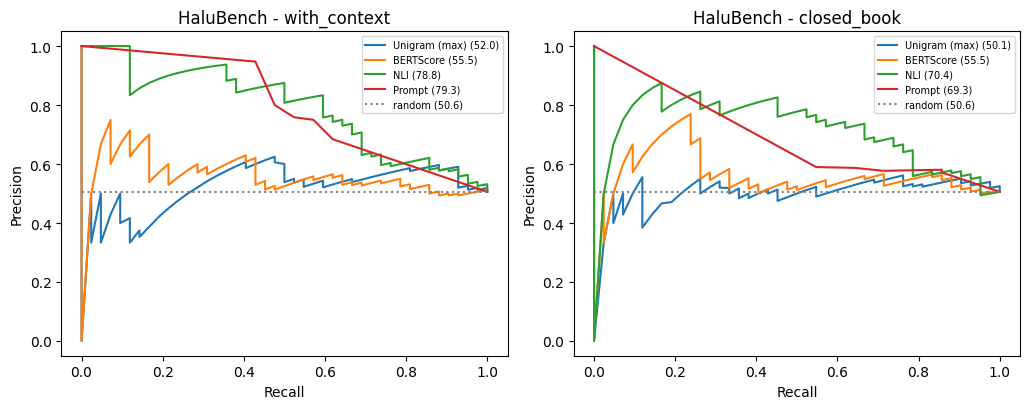

In [13]:
for mode in HB_MODES:
    print(f"################ {mode} ################")
    for metric in ("AUROC", "AUC_PR"): show_pivot(HB_RES[mode], "sentence", metric); print()
pd.concat(HB_RES.values()).to_csv(os.path.join(RESULTS_DIR, "ext_halubench_results.csv"), index=False)

fig, axes = plt.subplots(1, len(HB_MODES), figsize=(5.2 * len(HB_MODES), 4.2), squeeze=False)
for ax, mode in zip(axes[0], HB_MODES):
    y = np.array([it["resp_label"] for it in HB[mode]])
    for method, sc in HB_SC[mode].items():
        s = np.array([sc[it["id"]][0] for it in HB[mode]]); P, R, _ = precision_recall_curve(y, s); ax.plot(R, P, label=f"{method} ({100 * auc(R, P):.1f})")
    ax.hlines(y.mean(), 0, 1, colors="grey", linestyles="dotted", label=f"random ({100 * y.mean():.1f})")
    ax.set_title(f"HaluBench - {mode}"); ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "ext_halubench_pr_curves.png"), dpi=150); plt.show()

# **Effect of the number of samples**

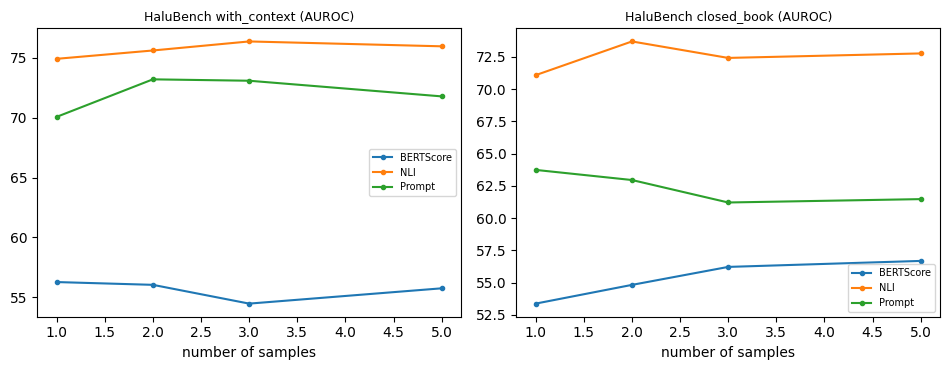

In [14]:
def ablate(items, MT, metric, level="sentence"):
    Ns = [n for n in (1, 2, 3, 5, 7, 10, 15, 20) if n <= N_SAMPLES]
    curves = {}
    for method, mats in MT.items():
        vals = []
        for n in Ns:
            sc = {i: ((1.0 - M[:, :n].mean(axis=1)) if method == "BERTScore" else M[:, :n].mean(axis=1)) for i, M in mats.items()}
            r = evaluate_items(items, sc, level, None, n_boot=0); vals.append(r[metric])
        curves[method] = vals
    return Ns, curves

panels = [(f"HaluBench {mode} (AUROC)", HB[mode], HB_MT[mode], "AUROC") for mode in HB_MODES if HB_MT.get(mode)]
if panels:
    fig, axes = plt.subplots(1, len(panels), figsize=(4.8 * len(panels), 3.8), squeeze=False)
    for ax, (title, items, MT, metric) in zip(axes[0], panels):
        Ns, curves = ablate(items, MT, metric)
        for m, v in curves.items(): ax.plot(Ns, v, marker="o", ms=3, label=m)
        ax.set_title(title, fontsize=9); ax.set_xlabel("number of samples"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "ext_halubench_num_samples.png"), dpi=150); plt.show()

# **Comparison with the WikiBio replication**

In [15]:
rows = []
def add(dataset, df, level="sentence", group="ALL"):
    for _, r in df[(df.level == level) & (df.group == group)].iterrows():
        rows.append({"dataset": dataset, "method": r["method"], "AUC-PR": r["AUC_PR"], "random (positive rate)": r["prevalence"],
                     "lift": r["AUC_PR"] - r["prevalence"], "AUROC": r["AUROC"], "n_items": r["n_items"]})
for mode in HB_MODES: add(f"HaluBench - answers ({mode})", HB_RES[mode])

sp = next((p for p in (os.path.join(d, "summary.json") for d in WIKIBIO_DIRS) if os.path.exists(p)), None)
if sp:
    print("WikiBio numbers read from", sp)
    t2 = json.load(open(sp)).get("table2", {})
    for name, m in t2.items():
        if m.get("NonFact") is not None:
            short = {"SelfCheck-Unigram (max)": "Unigram (max)", "SelfCheck-BERTScore": "BERTScore", "SelfCheck-NLI": "NLI"}.get(name, "Prompt" if "Prompt" in name else None)
            if short: rows.append({"dataset": "WikiBio - sentences (GPT-3), NonFact", "method": short, "AUC-PR": m["NonFact"], "random (positive rate)": 72.96,
                                   "lift": m["NonFact"] - 72.96, "AUROC": np.nan, "n_items": m.get("n_passages")})
else:
    print("summary.json from the replication notebook not found in", WIKIBIO_DIRS, "- WikiBio rows omitted")
SUMMARY = pd.DataFrame(rows).sort_values(["dataset", "method"])
display(SUMMARY.round(1).style.hide(axis="index"))
SUMMARY.to_csv(os.path.join(RESULTS_DIR, "ext_summary_halubench_vs_wikibio.csv"), index=False)

WikiBio numbers read from /content/drive/MyDrive/ExistingDatasets/summary.json


dataset,method,AUC-PR,random (positive rate),lift,AUROC,n_items
HaluBench - answers (closed_book),BERTScore,55.500000,50.600000,4.900000,56.700000,83.000000
HaluBench - answers (closed_book),NLI,70.400000,50.600000,19.800000,72.800000,83.000000
HaluBench - answers (closed_book),Prompt,69.300000,50.600000,18.700000,61.500000,83.000000
HaluBench - answers (closed_book),Unigram (max),50.100000,50.600000,-0.500000,53.000000,83.000000
HaluBench - answers (with_context),BERTScore,55.500000,50.600000,4.900000,55.700000,83.000000
HaluBench - answers (with_context),NLI,78.800000,50.600000,28.200000,76.000000,83.000000
HaluBench - answers (with_context),Prompt,79.300000,50.600000,28.700000,71.800000,83.000000
HaluBench - answers (with_context),Unigram (max),52.000000,50.600000,1.400000,57.500000,83.000000
"WikiBio - sentences (GPT-3), NonFact",BERTScore,81.200000,73.000000,8.200000,nan,238.000000
"WikiBio - sentences (GPT-3), NonFact",NLI,92.500000,73.000000,19.500000,nan,238.000000
